# Crossmatch Rubin DP2 footprint with an ra,dec list

Takes an input variable named CATALOG. Assumes you have a file called "targets_{CATALOG}.csv" containing two columns titled ra,dec with the coordinates of each galaxy you'd like to find. The notebook then defines several helper functions and checks the DP1 and DP2 tracts for your input CATALOG. If you'd only like to check one of the data previews, use the TO_RUN variable at the top of cell 4. Each galaxy is given a Galaxy ID (gid), used as an identifier throughout this project. The output is saved as {CATALOG}_rubin_coverage.csv, and an optional sky plot is available in cell 6 to check where the matches are on sky.

## 1. Setup

In [21]:
import numpy as np
import astropy.units as u
from astropy.table import Table
from astropy.coordinates import SkyCoord, search_around_sky
import lsst.sphgeom as sphgeom

## 2. Load your RA/Dec list

### Editable variables:
{CATALOG}: File prefix\
{INPUT_FILE}: Input csv\
{RA_COL}, {DEC_COL}: Column names in your {INPUT_FILE} that contain right ascensions and declinations

In [1]:
CATALOG = "greene"                    
INPUT_FILE = f"targets_{CATALOG}.csv"  
RA_COL, DEC_COL = "ra", "dec"           
EXTRA_COLS = []                         # e.g. ["name", "paper"]
MATCH_RADIUS_ARCSEC = 2.0               # Object match tolerance in Arcsec

try:
    gal_in = Table.read(INPUT_FILE)
except Exception:
    gal_in = Table.read(INPUT_FILE, format="ascii")   

ra_raw, dec_raw = gal_in[RA_COL], gal_in[DEC_COL]
if ra_raw.dtype.kind in "fiu":
    coords = SkyCoord(np.asarray(ra_raw, float), np.asarray(dec_raw, float), unit="deg")
else:
    coords = SkyCoord(np.asarray(ra_raw).astype(str), np.asarray(dec_raw).astype(str),
                      unit=(u.hourangle, u.deg))

gal = Table()
gal["gid"] = np.arange(len(gal_in), dtype=np.int64)
for c in EXTRA_COLS:
    gal[c] = gal_in[c]
gal["ra"] = coords.ra.deg
gal["dec"] = coords.dec.deg
gal["ra"].format = gal["dec"].format = ".5f"


if len(coords) > 1:
    _, d2d, _ = coords.match_to_catalog_sky(coords, nthneighbor=2)
    gal["dup_within_1as"] = d2d.arcsec < 1.0
else:
    gal["dup_within_1as"] = False

print(f"{len(gal)} positions loaded, {int(gal['dup_within_1as'].sum())} have another entry within 1 arcsec")
print(f"RA range {gal['ra'].min():.2f}-{gal['ra'].max():.2f}, Dec range {gal['dec'].min():.2f}-{gal['dec'].max():.2f}")


upload = Table({"gid": gal["gid"], "ra": gal["ra"], "dec": gal["dec"]})

NameError: name 'Table' is not defined

## 3. Helper functions

In [40]:
RELEASES = {
    "dp1": dict(obs_collection="LSST.DP1", fov_radius_deg=0.40),   # LSSTComCam (~0.5 deg^2)
    "dp2": dict(obs_collection="LSST.DP2", fov_radius_deg=1.75),   # LSSTCam (~9.6 deg^2)
}

### Initialize the tap client
def get_tap(release):
    # RSPDiscovery 
    try:
        from lsst.rsp import RSPDiscovery
        service = RSPDiscovery(release).get_tap_client()
    except Exception as err:
        print(f"RSPDiscovery('{release}') unavailable ({err}); using get_tap_service('tap')")
        from lsst.rsp import get_tap_service
        service = get_tap_service("tap")
    assert service is not None
    return service

### Run a tap query
def run_query(service, query, uploads=None):
    job = service.submit_job(query, uploads=uploads)
    job.run()
    job.wait(phases=["COMPLETED", "ERROR"])
    if job.phase == "ERROR":
        job.raise_if_error()
    result = job.fetch_result().to_table()
    try:
        job.delete()
    except Exception:
        pass
    return result

### Convert an ra,dec coordinate pair to a unit vector
def _uv(ra, dec):
    return sphgeom.UnitVector3d(sphgeom.LonLat.fromDegrees(float(ra), float(dec)))

### Just some formatting that otherwise breaks the code...
def parse_s_region(s_region):
    vals = []
    for tok in str(s_region).replace("(", " ").replace(")", " ").replace(",", " ").split():
        try:
            vals.append(float(tok))
        except ValueError:
            pass
    radec = np.array(vals).reshape(-1, 2)
    return sphgeom.ConvexPolygon.convexHull([_uv(r, d) for r, d in radec])

### Run a SQL-like query to check every COADD tract and patch from DP2
def coadd_coverage(service, release, coords):
    patches = run_query(service,
        f"SELECT lsst_tract, lsst_patch, s_ra, s_dec, s_region FROM {release}.CoaddPatches")
    print(f"  {release}.CoaddPatches: {len(patches)} patches")
    pcen = SkyCoord(np.asarray(patches["s_ra"], float), np.asarray(patches["s_dec"], float), unit="deg")
    
    ### Then check if each object is in the tract to within 0.25deg and return hits
    
    ig, ip, _, _ = search_around_sky(coords, pcen, 0.25 * u.deg)
    hits = [[] for _ in range(len(coords))]
    poly_cache = {}
    for g, p in zip(ig, ip):
        if p not in poly_cache:
            poly_cache[p] = parse_s_region(patches["s_region"][p])
        if poly_cache[p].contains(_uv(coords.ra.deg[g], coords.dec.deg[g])):
            hits[g].append((int(patches["lsst_tract"][p]), int(patches["lsst_patch"][p])))
    return hits

### Check for a deep coadd for each hit (does the object have deep imaging or just a single visit?
def coadd_bands(service, release, hits):
    tracts = sorted({t for h in hits for t, _ in h})
    if not tracts:
        return {}
    query = f'''SELECT lsst_tract, lsst_patch, lsst_band FROM ivoa.ObsCore
        WHERE obs_collection = '{RELEASES[release]["obs_collection"]}'
        AND dataproduct_subtype = 'lsst.deep_coadd'
        AND lsst_tract IN ({", ".join(str(t) for t in tracts)})'''
    try:
        obs = run_query(service, query)
    except Exception as err:
        print(f"  ObsCore band lookup failed ({err}); leaving bands blank")
        return {}
    bands = {}
    for t, p, b in zip(obs["lsst_tract"], obs["lsst_patch"], obs["lsst_band"]):
        bands.setdefault((int(t), int(p)), set()).add(str(b))
    return bands

### Then check for single visit images as a backup
def visit_counts(service, release, coords):
    try:
        visits = run_query(service, f"SELECT visit, ra, dec, band FROM {release}.Visit")
    except Exception as err:
        print(f"  Visit lookup failed ({err}); skipping single-epoch check")
        return np.full(len(coords), -1), [""] * len(coords)
    print(f"  {release}.Visit: {len(visits)} visits")
    vcen = SkyCoord(np.asarray(visits["ra"], float), np.asarray(visits["dec"], float), unit="deg")
    ig, iv, _, _ = search_around_sky(coords, vcen, RELEASES[release]["fov_radius_deg"] * u.deg)
    n = np.bincount(ig, minlength=len(coords))
    vb = [set() for _ in range(len(coords))]
    for g, v in zip(ig, iv):
        vb[g].add(str(visits["band"][v]))
    return n, ["".join(b for b in "ugrizy" if b in s) for s in vb]

### Then get all the imaging of objects that pass the tests (hits)
def object_match(service, release, upload, radius_arcsec):

    r_deg = radius_arcsec / 3600.0
    query = f'''
        SELECT ut.gid AS gid, obj.objectId, obj.coord_ra, obj.coord_dec,
               obj.refExtendedness, obj.r_cModelMag, obj.i_cModelMag
        FROM {release}.Object AS obj
        JOIN TAP_UPLOAD.ut AS ut
        ON DISTANCE(POINT('ICRS', obj.coord_ra, obj.coord_dec),
                    POINT('ICRS', ut.ra, ut.dec)) < {r_deg:.8f}
        '''
    res = run_query(service, query, uploads={"ut": upload})
    print(f"  {release}.Object: {len(res)} matches for {len(np.unique(res['gid'])) if len(res) else 0} inputs")
    best = {}
    if len(res):
        lookup = {int(g): i for i, g in enumerate(upload["gid"])}
        ri = np.array([lookup[int(g)] for g in res["gid"]])
        sep = SkyCoord(np.asarray(res["coord_ra"], float), np.asarray(res["coord_dec"], float), unit="deg") \
            .separation(SkyCoord(np.asarray(upload["ra"])[ri], np.asarray(upload["dec"])[ri], unit="deg")).arcsec
        for k in range(len(res)):
            g = int(res["gid"][k])
            if g not in best or sep[k] < best[g][1]:
                best[g] = (k, sep[k])
    return res, best

## 4. Run for DP1 and DP2

### Editable Variables:
{TO_RUN}: List of strings ["dp1","dp2"] with the desired DR to crossmatch. Most users are best served by only using [dp2].

In [41]:
TO_RUN = ["dp2"]
out = gal.copy()

for rel in TO_RUN:
    print(f"=== {rel} ===")
    service = get_tap(rel)

    hits = coadd_coverage(service, rel, coords)
    bands = coadd_bands(service, rel, hits)
    out[f"{rel}_in_coadd"] = np.array([len(h) > 0 for h in hits])
    out[f"{rel}_tract_patch"] = [";".join(f"{t}.{p}" for t, p in h) for h in hits]
    out[f"{rel}_coadd_bands"] = ["".join(b for b in "ugrizy" if any(b in bands.get(tp, ()) for tp in h))
                                 for h in hits]

    nvis, vbands = visit_counts(service, rel, coords)
    out[f"{rel}_n_visits_approx"] = nvis
    out[f"{rel}_visit_bands"] = vbands

    res, best = object_match(service, rel, upload, MATCH_RADIUS_ARCSEC)
    n = len(out)
    oid = np.zeros(n, dtype=np.int64)
    sep = np.full(n, np.nan)
    ext = np.full(n, np.nan)
    rmag = np.full(n, np.nan)
    imag = np.full(n, np.nan)
    for g, (k, s) in best.items():
        oid[g], sep[g] = res["objectId"][k], s
        ext[g] = res["refExtendedness"][k]
        rmag[g], imag[g] = res["r_cModelMag"][k], res["i_cModelMag"][k]
    out[f"{rel}_objectId"] = oid
    out[f"{rel}_sep_arcsec"] = sep
    out[f"{rel}_refExtendedness"] = ext
    out[f"{rel}_r_cModelMag"] = rmag
    out[f"{rel}_i_cModelMag"] = imag
    for c in ("sep_arcsec", "r_cModelMag", "i_cModelMag"):
        out[f"{rel}_{c}"].format = ".2f"

    print(f"  in deep-coadd footprint: {int(out[f'{rel}_in_coadd'].sum())}")
    print(f"  near >=1 visit (approx): {int((nvis > 0).sum())}")
    print(f"  matched to an Object:    {int((oid > 0).sum())}")

=== dp2 ===
  dp2.CoaddPatches: 197105 patches
  dp2.Visit: 28698 visits
  dp2.Object: 1 matches for 1 inputs
  in deep-coadd footprint: 1
  near >=1 visit (approx): 6
  matched to an Object:    1


## 5. Summary and output

In [2]:
for rel in TO_RUN:
    covered = out[out[f"{rel}_in_coadd"] | (out[f"{rel}_n_visits_approx"] > 0) | (out[f"{rel}_objectId"] > 0)]
    print(f"\n=== {rel}: {len(covered)} galaxies with any coverage ===")
    if len(covered):
        cols = ["gid"] + EXTRA_COLS + ["ra", "dec", f"{rel}_in_coadd", f"{rel}_coadd_bands",
                f"{rel}_n_visits_approx", f"{rel}_objectId", f"{rel}_sep_arcsec", f"{rel}_r_cModelMag"]
        covered[cols].pprint_all()


    odd = out[out[f"{rel}_in_coadd"] & (out[f"{rel}_objectId"] == 0)]
    if len(odd):
        print(f"\n{len(odd)} {rel} galaxies are inside a coadd patch but have no Object match "
              f"(masked/bright-star region, missing bands, or deblending); check gid: {[int(g) for g in odd['gid']]}")

OUTPUT_FILE = f"{CATALOG}_rubin_coverage.csv"
out.write(OUTPUT_FILE, format="ascii.csv", overwrite=True)
print(f"\nWrote {OUTPUT_FILE} ({len(out)} rows)")

NameError: name 'TO_RUN' is not defined

## 6. Sky plot (optional)

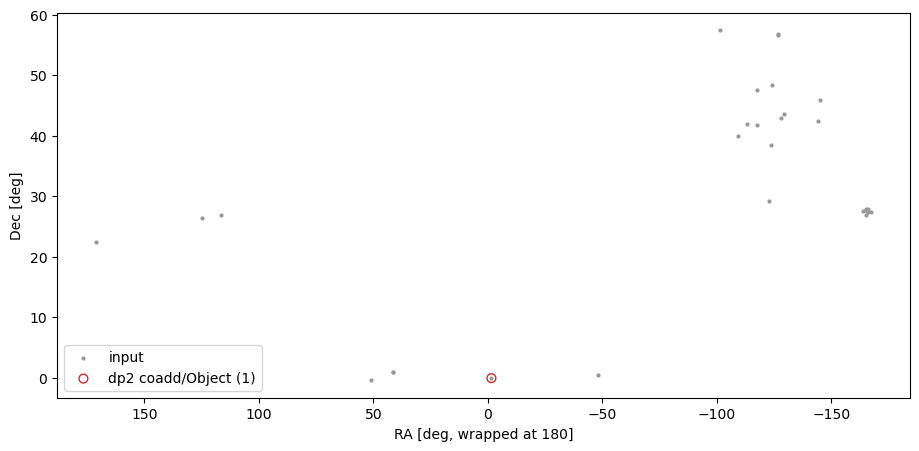

In [43]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))
wrap = lambda ra: np.where(ra > 180, ra - 360, ra)
ax.scatter(wrap(out["ra"]), out["dec"], s=4, c="0.6", label="input")
markers = {"dp1": ("s", "tab:blue"), "dp2": ("o", "tab:red")}
for rel in TO_RUN:
    sel = out[f"{rel}_in_coadd"] | (out[f"{rel}_objectId"] > 0)
    m, c = markers[rel]
    ax.scatter(wrap(out["ra"][sel]), out["dec"][sel], s=40, marker=m, facecolor="none",
               edgecolor=c, label=f"{rel} coadd/Object ({int(sel.sum())})")
ax.invert_xaxis()
ax.set_xlabel("RA [deg, wrapped at 180]")
ax.set_ylabel("Dec [deg]")
ax.legend(loc="lower left")
plt.show()